# 22. Data overview: the launch at every station

A first look at the launch for the whole network, in physical units:

* **record sections** of pressure (>0.5 Hz; infraBSU and Gem) and vertical ground velocity (>1 Hz;
  Trillium and SmartSolo), every channel sorted by distance from SLC-39B and scaled to its own peak
  (peak at the native sampling rate printed at right; display decimated to 100 samples/s); Gem overflow intervals (notebook 20) are shaded and blanked;
* **spectrograms** of pressure and vertical velocity at B01 (1.5 km).

All channels are instrument corrected (`cfg.instrument_correct`); SmartSolo verticals are sign-flipped to
the up-positive convention (notebook 50). Faulty channels (B03 Centaur) and unconnected inputs are omitted.

Output (`cfg.OUT_DIR`): `data_overview.png`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

import artemis2_config as cfg

L = cfg.LAUNCHTIME
OUT = cfg.OUT_DIR / "22_data_overview"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
T0, T1 = -10, 150
stations = cfg.station_table()

In [2]:
raw = cfg.launch_stream_raw()
clips = cfg.stream_clip_intervals(raw)
st = cfg.instrument_correct(raw)
for tr in st:
    if tr.stats.location == '--':
        tr.stats.location = ''
    if tr.stats.channel == 'DPZ':
        tr.data = -tr.data            # SmartSolo vertical polarity is reversed
EXCLUDE = {'1R.B03.00.CD0', '1R.B03.00.CHZ'}

def keep(tr):
    cha, sta = tr.stats.channel, tr.stats.station
    if tr.id in EXCLUDE or sta not in stations.index:
        return None
    if cha.startswith('HD') or cha == 'CD0':
        return 'pressure'
    if cha in ('CHZ', 'DPZ'):
        return 'velocity'
    return None

groups = {'pressure': [], 'velocity': []}
for tr in st:
    k = keep(tr)
    if not k:
        continue
    t = tr.copy()
    t.filter('highpass', freq=0.5 if k == 'pressure' else 1.0, corners=4, zerophase=True)
    full = t.slice(L + T0, L + T1)
    m_full = cfg.clip_mask(full, clips.get(tr.id, []))
    peak_full = np.nanmax(np.abs(np.where(m_full, np.nan, full.data.astype(float))))   # at the native rate
    if t.stats.sampling_rate > 100:
        t.filter('lowpass', freq=40, corners=8, zerophase=True)
        t.resample(100, no_filter=True)
    t = t.slice(L + T0, L + T1)
    mask = cfg.clip_mask(t, clips.get(tr.id, []))
    t.data = np.where(mask, np.nan, t.data.astype(float))
    groups[k].append((stations.distance_km[tr.stats.station], tr.id, t, peak_full))
for k in groups:
    groups[k].sort(key=lambda x: (x[0], x[1]))
print({k: len(v) for k, v in groups.items()})

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/ksclib/src/ksclib/data.py:34: UserWarning: SKIPPED unreadable SDS file /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091 (InternalMSEEDParseTimeError)
  warnings.warn(f"SKIPPED unreadable SDS file {path} ({type(exc).__name__})")


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


... (16 outputs left out)

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


{'pressure': 21, 'velocity': 13}


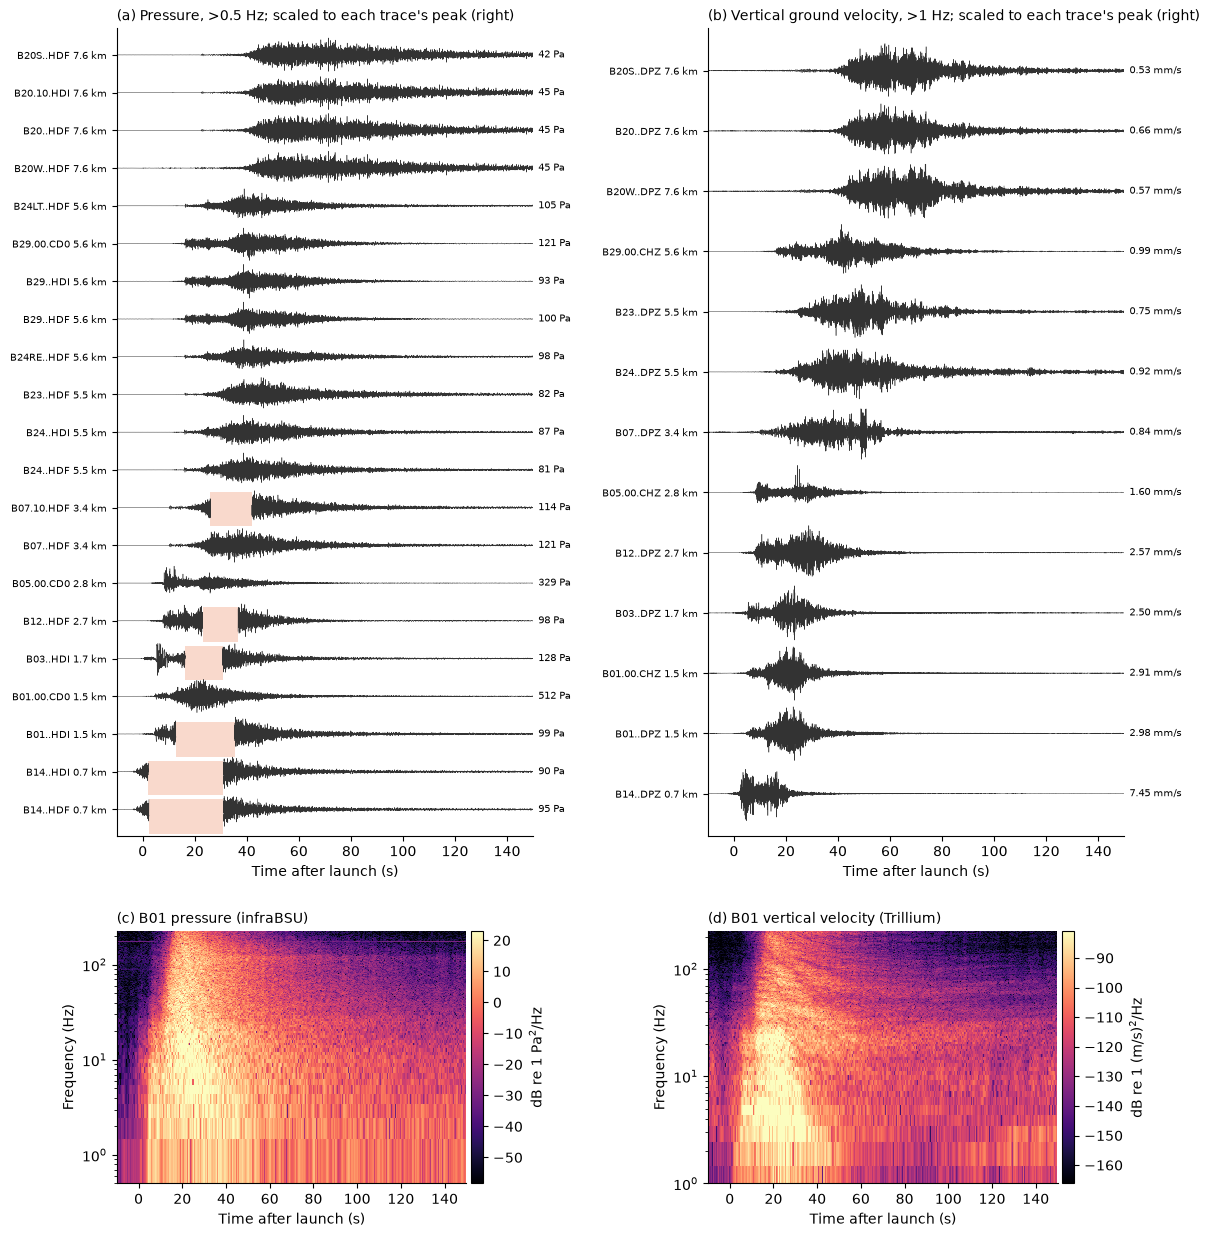

In [3]:
INST = {'CD0': 'infraBSU', 'HDF': 'Gem', 'HDI': 'Gem (tote)', 'CHZ': 'Trillium', 'DPZ': 'SmartSolo'}
fig = plt.figure(figsize=(13, 15))
gs = fig.add_gridspec(2, 2, height_ratios=[3.2, 1], hspace=0.18, wspace=0.42)
for col, (k, unit, scale, fmt) in enumerate((('pressure', 'Pa', 1, '{:.0f} Pa'),
                                             ('velocity', 'mm/s', 1e3, '{:.2f} mm/s'))):
    ax = fig.add_subplot(gs[0, col])
    for i, (d, sid, t, peak_full) in enumerate(groups[k]):
        y = t.data * scale
        pk = np.nanmax(np.abs(y))
        tt = t.times() + T0
        ax.plot(tt, i + 0.45 * y / pk, color='#333333', lw=0.35)
        for a, b in clips.get(sid, []):
            ax.axvspan(a - L, b - L, ymin=(i + 0.05) / len(groups[k]), ymax=(i + 0.95) / len(groups[k]),
                       color='#eb6834', alpha=0.25, lw=0)
        ax.text(T1 + 2, i, fmt.format(peak_full * scale), va='center', fontsize=7)
    ax.set_yticks(range(len(groups[k])))
    ax.set_yticklabels([f"{sid.replace('1R.', '')} {d:.1f} km" for d, sid, _, _ in groups[k]], fontsize=7)
    ax.set_ylim(-0.7, len(groups[k]) - 0.3)
    ax.set_xlim(T0, T1)
    ax.set_xlabel('Time after launch (s)')
    ax.set_title(('(a) Pressure, >0.5 Hz' if k == 'pressure' else '(b) Vertical ground velocity, >1 Hz') +
                 '; scaled to each trace\'s peak (right)', fontsize=10, loc='left')
for col, (sid, lab, unit, flo) in enumerate((('1R.B01.00.CD0', '(c) B01 pressure (infraBSU)', 'Pa$^2$/Hz', 0.5),
                                             ('1R.B01.00.CHZ', '(d) B01 vertical velocity (Trillium)', '(m/s)$^2$/Hz', 1.0))):
    tr = st.select(id=sid)[0].copy()
    tr.filter('highpass', freq=flo, corners=4, zerophase=True)
    s = tr.slice(L + T0, L + T1)
    f, tt, Sxx = spectrogram(s.data.astype(float), s.stats.sampling_rate, nperseg=512, noverlap=384)
    db = 10 * np.log10(Sxx + 1e-30)
    ax = fig.add_subplot(gs[1, col])
    im = ax.pcolormesh(tt + T0, f, db, shading='auto', cmap='magma', vmin=np.percentile(db, 5), vmax=np.percentile(db, 99.5))
    ax.set(yscale='log', ylim=(flo, 225), xlim=(T0, T1), ylabel='Frequency (Hz)', xlabel='Time after launch (s)')
    ax.set_title(lab, fontsize=10, loc='left')
    fig.colorbar(im, ax=ax, pad=0.01, label=f'dB re 1 {unit}')
fig.savefig(OUT / 'data_overview.png', dpi=200, bbox_inches='tight')